## 1. Importing Required Libraries

Before teaching a machine to predict prices, we need the right tools.

We will use Python libraries for data handling, visualization, Machine Learning, model evaluation, and saving our trained model.

### Why do we need these libraries?

- **Pandas:** To load and manage our agricultural dataset.
- **NumPy:** To perform numerical operations.
- **Matplotlib and Seaborn:** To visualize results.
- **Scikit-learn:** To prepare data, train models, and evaluate predictions.
- **Joblib:** To save the trained model so that our application can use it later.

Let's import the required libraries.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


## 3. Loading the Agricultural Dataset

Our Machine Learning model needs examples from which it can learn.

For this project, we are using an agricultural bidding dataset containing information about crop listings and their starting bid prices.

Each row represents a crop listing, while each column describes one characteristic of that listing.

For example, a record may contain:

- The district where the crop was produced
- The type and variety of crop
- The quantity available
- The quality score
- Transportation expenses
- Historical market price
- The starting bid price

We will load the dataset and inspect its structure before training any model.

**Our objective:** Understand what information is available to help predict the starting bid price.

In [6]:
df = pd.read_csv("jk_farm_bidding_eda_dataset.csv")

df.head()

,lot_id,listing_date,district,crop,variety,grade,season,quantity_quintals,quality_score,storage_type,distance_to_major_mandi_km,transport_cost_per_quintal_inr,rainfall_mm_30d,avg_temperature_c,market_arrival_quintals,historical_modal_price_inr_per_quintal,starting_bid_price_inr_per_quintal
0,JKLOT006370,2025-12-19,Pulwama,Plum,Local,B,Winter,25.3,71.7,Cold Storage,22.2,1.55,25.3,6.9,58.2,5113.48,4712.10
1,JKLOT017179,2023-02-11,Udhampur,Maize,Yellow,B,Winter,14.1,70.7,NaN,82.5,9.60,23.5,7.3,32.9,2861.61,2746.23
2,JKLOT012536,2024-01-28,Rajouri,Potato,Local,A,Winter,53.8,76.1,NaN,81.2,8.40,13.2,15.4,311.7,1559.27,1248.77
3,JKLOT018416,2024-10-15,Budgam,Pear,Patharnakh,A,Autumn,334.8,57.4,Cold Storage,135.9,11.65,9.2,18.6,115.9,6076.14,5346.12
4,JKLOT012664,2024-04-06,Kupwara,Plum,Santa Rosa,Mixed,Spring,18.7,76.9,NaN,47.5,5.40,8.5,21.6,185.4,6396.93,5434.49


In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 25180
Columns: 17


## Cleaning and Standardizing Categorical Data

Imagine two farmers list their crops on AgriSense.

One enters the district as `shopian`, while another enters it as `Shopian`.

Similarly, a crop might be entered as `apple`, `Apple`, or ` APPLE `.

Although these values represent the same information, Python may treat them as different categories.

This can create unnecessary confusion when our Machine Learning model learns from the dataset.

### What are we going to do?

First, we identify the categorical columns that contain text-based information:

- `district`: Location of the crop listing.
- `crop`: Name of the crop.
- `variety`: Specific variety of the crop.
- `grade`: Quality classification.
- `season`: Agricultural season.
- `storage_type`: Type of storage used.

Next, we standardize these values using Python string operations.

### Understanding the cleaning operations

1. **Convert to string:** `.astype("string")` ensures that the selected columns use a consistent text data type.
2. **Remove extra spaces:** `.str.strip()` removes unnecessary spaces from the beginning and end of each value.
3. **Title case:** `.str.title()` converts the first letter of each word to uppercase. We use it for district, crop, season, and storage type.
4. **Uppercase:** `.str.upper()` converts grade values into uppercase letters, such as `a` into `A`.

### Why is this important?

We want the same category to have the same representation throughout our dataset.

For example:

| Before cleaning | After cleaning |
|---|---|
| `shopian` | `Shopian` |
| ` APPLE ` | `Apple` |
| `autumn` | `Autumn` |
| `a` | `A` |
| `cold storage` | `Cold Storage` |

By standardizing categorical data, we reduce inconsistent labels and prepare our dataset for the next Machine Learning preprocessing steps.

**Our goal:** Make sure that AgriSense recognizes identical categories as the same information, rather than treating small spelling or formatting differences as separate categories.

In [8]:
categorical_columns = [
    "district",
    "crop",
    "variety",
    "grade",
    "season",
    "storage_type"
]

for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip()

df["district"] = df["district"].str.title()
df["crop"] = df["crop"].str.title()
df["grade"] = df["grade"].str.upper()
df["season"] = df["season"].str.title()
df["storage_type"] = df["storage_type"].str.title()

print("Categorical data cleaned!")

Categorical data cleaned!


## Identifying and Handling Invalid Values

Imagine a farmer listing 100 quintals of apples on AgriSense.

The listing contains a quality score of 120, a distance of -15 km, or a crop quantity of -5 quintals.

Do these values make sense?

No. A quality score should be between 0 and 100, distance cannot be negative, and a valid crop listing must have a positive quantity.

If we allow such values into our Machine Learning model, it may learn from incorrect information and produce unreliable predictions.

Therefore, before training our model, we need to identify and handle logically invalid values.

### What problems are we checking?

**1. Invalid Quality Scores**

The `quality_score` column represents crop quality.

- Valid range: 0 to 100.
- Invalid values: Below 0 or above 100.

We replace invalid quality scores with missing values (`np.nan`).

**2. Invalid Mandi Distance**

The `distance_to_major_mandi_km` column represents the distance between the crop location and a major agricultural market.

- Valid values: Zero or positive numbers.
- Invalid values: Negative distances.

We replace negative distances with missing values.

**3. Invalid Crop Quantities**

The `quantity_quintals` column represents the amount of crop available for bidding.

- Valid values: Greater than zero.
- Invalid values: Zero or negative quantities.

We replace these invalid quantities with missing values.

**4. Removing Records Without a Starting Bid Price**

Our main objective is to predict the starting bid price.

If a record does not contain a starting bid price, the model cannot learn the correct target value from that record.

Therefore, we remove rows where `starting_bid_price_inr_per_quintal` is missing.

### Why use `np.nan`?

`np.nan` represents a missing numerical value in Python.

Instead of keeping an impossible value, we mark it as missing so that it can be handled later through appropriate preprocessing techniques.

### Our objective

We are not deleting every row containing an invalid feature. We are identifying incorrect values, marking them as missing, and removing only records where the target price is unavailable.

This helps us prepare more reliable data for Machine Learning.

In [9]:
df.loc[
    (df["quality_score"] < 0) |
    (df["quality_score"] > 100),
    "quality_score"
] = np.nan

df.loc[
    df["distance_to_major_mandi_km"] < 0,
    "distance_to_major_mandi_km"
] = np.nan

df.loc[
    df["quantity_quintals"] <= 0,
    "quantity_quintals"
] = np.nan

df = df.dropna(
    subset=["starting_bid_price_inr_per_quintal"]
)

print("Invalid values handled!")

Invalid values handled!


## Extracting Useful Information from Listing Dates

Imagine two farmers list their crops on AgriSense.

One farmer lists apples in October, while another lists cherries in June.

Could the month in which a crop is listed help our Machine Learning model understand seasonal price patterns?

Possibly! Agricultural prices can vary depending on the season, crop availability, and market demand.

Our dataset contains a `listing_date` column. However, instead of using the complete date directly, we can extract useful information from it.

### What are we going to do?

We will perform three operations:

**1. Convert the Listing Date**

We use `pd.to_datetime()` to convert the `listing_date` column into Pandas datetime format.

This allows Python to recognize the values as dates rather than ordinary text.

We also use `errors="coerce"` so that any invalid date is converted into a missing value (`NaT`) instead of causing an error.

**2. Extract the Year**

Using `.dt.year`, we extract the year from each listing date.

For example:

- 2025-10-15 → 2025
- 2026-06-20 → 2026

**3. Extract the Month**

Using `.dt.month`, we extract the numerical month.

For example:

- January → 1
- June → 6
- October → 10
- December → 12

### Why is this useful for AgriSense?

The year and month provide additional time-related information about each crop listing.

Our Machine Learning model can use these features along with crop type, district, quantity, quality, and historical market price when estimating a starting bid price.

**Our goal:** Convert date information into useful numerical features that our Machine Learning model can understand.

In [10]:
df["listing_date"] = pd.to_datetime(
    df["listing_date"],
    errors="coerce"
)

df["year"] = df["listing_date"].dt.year
df["month"] = df["listing_date"].dt.month

df[["listing_date", "year", "month"]].head()

,listing_date,year,month
0,2025-12-19,2025,12
1,2023-02-11,2023,2
2,2024-01-28,2024,1
3,2024-10-15,2024,10
4,2024-04-06,2024,4


In [11]:
features = [
    "district",
    "crop",
    "variety",
    "grade",
    "season",
    "quantity_quintals",
    "quality_score",
    "storage_type",
    "distance_to_major_mandi_km",
    "transport_cost_per_quintal_inr",
    "rainfall_mm_30d",
    "avg_temperature_c",
    "market_arrival_quintals",
    "historical_modal_price_inr_per_quintal",
    "year",
    "month"
]

X = df[features]

y = df["starting_bid_price_inr_per_quintal"]

print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (25180, 16)
Target variable: (25180,)


## Identifying Numerical and Categorical Features

Now that we have selected the input features for AgriSense, we need to understand what type of information each feature contains.

Imagine our farmer provides the following crop details:

- District: Shopian
- Crop: Apple
- Grade: A
- Quantity: 100 quintals
- Quality Score: 90
- Temperature: 15°C

Some of these values represent measurable quantities, while others represent names or categories.

Machine Learning models need us to handle these two types of information differently during preprocessing.

### 1. Numerical Features

Numerical features contain numbers that represent measurable quantities.

Examples from our dataset include:

- `quantity_quintals`
- `quality_score`
- `distance_to_major_mandi_km`
- `transport_cost_per_quintal_inr`
- `rainfall_mm_30d`
- `avg_temperature_c`
- `market_arrival_quintals`
- `historical_modal_price_inr_per_quintal`
- `year`
- `month`

We use `select_dtypes(include=np.number)` to automatically identify numerical columns.

### 2. Categorical Features

Categorical features represent labels, names, or groups rather than measurable quantities.

Examples include:

- `district`
- `crop`
- `variety`
- `grade`
- `season`
- `storage_type`

We use `select_dtypes(include="object")` to identify columns with the object data type.

### Why do we separate them?

Because these two types require different preprocessing techniques.

- Numerical features: Missing values will be handled using the median.
- Categorical features: Missing values will be handled using the most frequent value, followed by One-Hot Encoding.

This separation helps us organize our data before building the preprocessing pipeline.

**Our goal:** Identify which features contain numerical information and which contain categorical information so that each can be processed correctly.

In [12]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['quantity_quintals', 'quality_score', 'distance_to_major_mandi_km', 'transport_cost_per_quintal_inr', 'rainfall_mm_30d', 'avg_temperature_c', 'market_arrival_quintals', 'historical_modal_price_inr_per_quintal', 'year', 'month']

Categorical Features:
[]


## Splitting the Dataset into Training and Testing Data

Now that we have identified our input features (X) and target variable (y), we are ready to prepare our data for Machine Learning.

Imagine teaching a student using a set of questions and then giving them a separate test to check what they have learned.

Machine Learning works in a similar way.

We divide our agricultural dataset into two parts:

### 1. Training Data (80%)

This portion is given to the Machine Learning model so it can learn patterns and relationships between crop characteristics and starting bid prices.

For example, the model learns from existing crop listings containing information about crop type, quantity, quality, district, and their corresponding starting bid prices.

### 2. Testing Data (20%)

This portion is kept separate from the training process.

After training, we use this data to check how accurately the model predicts starting bid prices for records it has not seen during training.

### Understanding the Parameters

- `test_size=0.20`: Reserves 20% of the dataset for testing and uses the remaining 80% for training.
- `random_state=42`: Ensures that the same random split can be reproduced when we run the code again.

### Why is this important?

If we evaluate a model using only the data it learned from, its performance may appear better than it actually is.

By keeping testing data separate, we get a more meaningful evaluation of how the model performs on unseen records.

**Our goal:** Train AgriSense using 80% of the available data and evaluate its predictions using the remaining 20%.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 20144
Testing records: 5036


## Preparing Numerical and Categorical Data for Machine Learning

We have divided our dataset into training and testing sets. Now we need to prepare the information so that our Machine Learning algorithms can understand it.

Remember that our agricultural dataset contains two different types of information:

- Numerical data, such as quantity, temperature, rainfall, and historical price.
- Categorical data, such as crop, district, variety, grade, and storage type.

These two types of data cannot be handled in exactly the same way.

Therefore, we will create separate preprocessing pipelines for numerical and categorical features.

### 1. Numerical Data Pipeline

Numerical columns may contain missing values.

For example, a crop listing might have its transportation cost or rainfall information missing.

We use **Median Imputation** to fill these missing numerical values.

The median is the middle value when all values are arranged in ascending order.

We choose the median because it is less affected by extremely high or low values than the mean.

### 2. Categorical Data Pipeline

Categorical columns may also contain missing values.

For example, a farmer might not provide the crop variety or storage type.

We use two operations:

**Most Frequent Imputation:** Replaces missing categorical values with the most frequently occurring value in that column.

**One-Hot Encoding:** Converts text categories into numerical indicator columns so that Machine Learning algorithms can process them.

We also use `handle_unknown="ignore"`.

This prevents errors if a new category appears during prediction that was not present during model training.

### 3. Combining Both Pipelines

Now we combine the numerical and categorical pipelines using `ColumnTransformer`.

It automatically applies:

- The numerical pipeline to numerical features.
- The categorical pipeline to categorical features.

### Why use a Pipeline?

A Pipeline organizes multiple preprocessing operations into a single workflow.

It also helps ensure that the same transformations are applied during model training and when AgriSense predicts the price of a new crop listing.

**Our goal:** Build one organized preprocessing system that can handle both numerical and categorical information before passing it to our Machine Learning models.

In [14]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [15]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


## Training Different Machine Learning Models

Our agricultural data is now cleaned, organized, and ready for Machine Learning.

We have also created a preprocessing pipeline that handles missing values and converts categorical information into numerical form.

Now comes the most important stage: **teaching the computer to predict crop starting bid prices.**

But which Machine Learning algorithm should we use?

Instead of choosing one algorithm without testing, we will train four different regression models and compare their performance.

### Model 1: Linear Regression

Imagine that crop prices follow a relatively simple mathematical relationship with the input features.

Linear Regression tries to learn this relationship by fitting a mathematical line or hyperplane to the training data.

It provides a simple baseline model against which we can compare more advanced algorithms.

### Model 2: Decision Tree Regressor

A Decision Tree works like a series of questions.

For example:

- Is the crop quantity greater than 50 quintals?
- Is the quality score above 80?
- Is the crop stored in cold storage?

Based on these conditions, the tree divides the data into smaller groups and generates a price prediction.

We set `max_depth=12` to limit how deep the tree can grow.

### Model 3: Random Forest Regressor

A single Decision Tree may make unstable predictions.

Random Forest addresses this by creating multiple Decision Trees and combining their predictions.

For our model, we use:

- `n_estimators=100`: Creates 100 decision trees.
- `max_depth=15`: Limits the maximum depth of each tree.
- `random_state=42`: Makes the model's randomness reproducible.
- `n_jobs=-1`: Uses all available CPU cores for parallel processing.

The combined predictions generally make Random Forest more stable than relying on one decision tree.

### Model 4: Gradient Boosting Regressor

Gradient Boosting takes a different approach.

Instead of building independent trees, it builds trees sequentially.

Each new tree attempts to correct the prediction errors made by the previous trees.

We use:

- `n_estimators=100`: Builds 100 boosting stages.
- `learning_rate=0.1`: Controls how much each new tree contributes.
- `max_depth=3`: Limits the depth of individual trees.
- `random_state=42`: Makes the process reproducible.

### Why are we training four models?

Every algorithm learns patterns differently.

By training all four models using the same training dataset, we can compare their performance and identify which one produces the most accurate predictions on our testing data.

**Our goal:** Find the most suitable regression model for estimating agricultural crop starting bid prices.

In [17]:
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)

print("Linear Regression trained!")

Linear Regression trained!


In [18]:
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=12,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

print("Decision Tree trained!")

Decision Tree trained!


In [19]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained!")

Random Forest trained!


In [20]:
gb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

print("Gradient Boosting trained!")

Gradient Boosting trained!


## Evaluating and Comparing Machine Learning Models

Our four Machine Learning models have completed their training.

But how do we know which model is performing best?

Imagine four students solving the same examination. All four have studied the same material, but their answers may differ in accuracy.

Similarly, our four models may produce different predictions for the same crop listings.

We need a common method to evaluate their performance.

### 1. Creating an Evaluation Function

Instead of writing the same evaluation code separately for every model, we create a function called `evaluate_model()`.

This function takes a trained model, testing features, and actual testing prices as input.

It generates predictions and calculates four performance metrics.

### 2. Understanding the Evaluation Metrics

**Mean Absolute Error (MAE)**

Measures the average absolute difference between actual and predicted prices.

For example, an MAE of ₹500 means that the model's predictions differ from actual prices by ₹500 per quintal on average.

A lower MAE is better.

**Mean Squared Error (MSE)**

Calculates the average of squared prediction errors.

It gives greater importance to large errors because the differences are squared.

A lower MSE is better.

**Root Mean Squared Error (RMSE)**

RMSE is the square root of MSE.

It expresses prediction error in the same unit as our target variable: INR per quintal.

A lower RMSE is better.

**R² Score**

Measures how much variation in the actual starting bid prices is explained by the model.

A score closer to 1 generally indicates a better fit.

### 3. Evaluating All Four Models

We create a dictionary containing our trained models:

- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting

Using a loop, we evaluate each model on the same testing dataset.

The results are stored in a list and converted into a Pandas DataFrame.

### 4. Ranking the Models

Finally, we sort the results using MAE in ascending order.

This places the model with the lowest Mean Absolute Error at the top.

The first model in the table will be our best-performing model according to MAE.

**Our goal:** Identify which Machine Learning algorithm predicts agricultural starting bid prices most accurately on the testing dataset.

In [21]:
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test, predictions
    )

    mse = mean_squared_error(
        y_test, predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test, predictions
    )

    return mae, mse, rmse, r2

In [22]:
models = {
    "Linear Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

results = []

for name, model in models.items():

    mae, mse, rmse, r2 = evaluate_model(
        model, X_test, y_test
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE"
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,850.757425,1.574874e+07,3968.468747,0.982964
2,Random Forest,906.726169,1.630993e+07,4038.555437,0.982357
3,Gradient Boosting,911.143263,1.636898e+07,4045.859421,0.982294
1,Decision Tree,1043.417851,1.953647e+07,4420.008064,0.978867


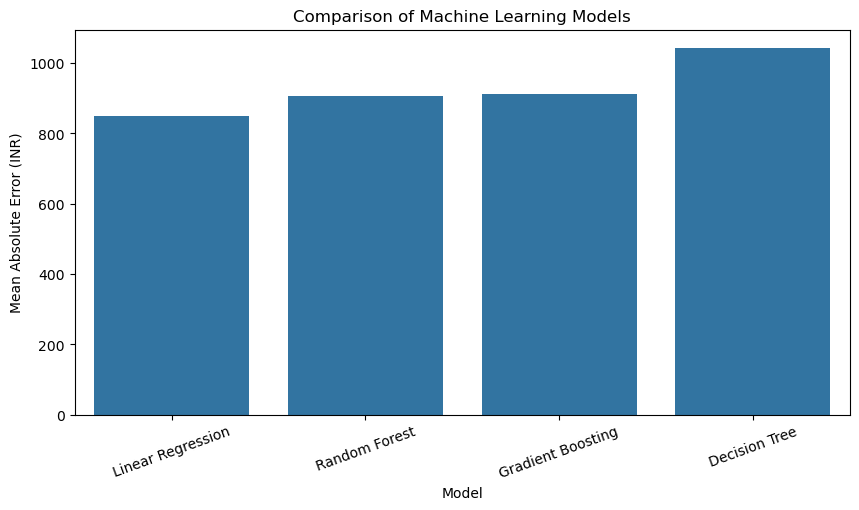

In [23]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("Comparison of Machine Learning Models")

plt.ylabel("Mean Absolute Error (INR)")

plt.xticks(rotation=20)

plt.show()

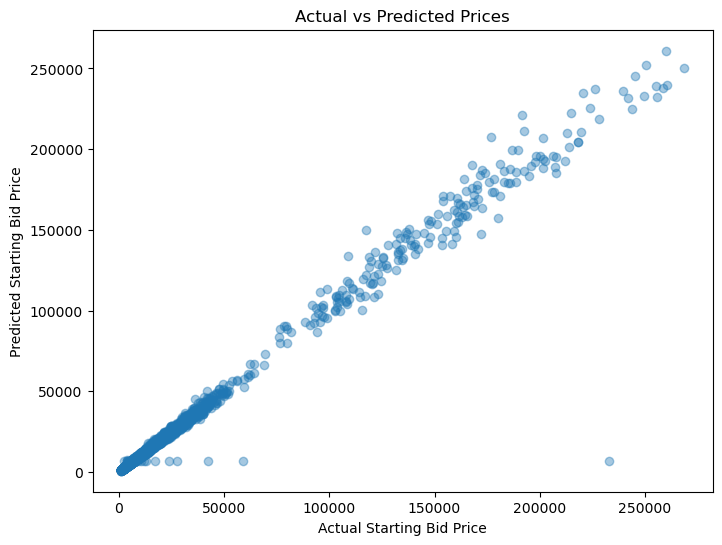

In [24]:
best_model_name = results_df.iloc[0]["Model"]

best_model = models[best_model_name]

predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.4
)

plt.xlabel("Actual Starting Bid Price")

plt.ylabel("Predicted Starting Bid Price")

plt.title("Actual vs Predicted Prices")

plt.show()

In [25]:
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/kisanbid_model.pkl"
)

print("Best model saved successfully!")
print("Selected model:", best_model_name)

Best model saved successfully!
Selected model: Linear Regression


In [33]:
new_crop = pd.DataFrame([{
    "district": "Shopian",
    "crop": "Apple",
    "variety": "Royal Delicious",
    "grade": "A",
    "season": "Autumn",
    "quantity_quintals": 100,
    "quality_score": 90,
    "storage_type": "Cold Storage",
    "distance_to_major_mandi_km": 25,
    "transport_cost_per_quintal_inr": 4,
    "rainfall_mm_30d": 30,
    "avg_temperature_c": 15,
    "market_arrival_quintals": 500,
    "historical_modal_price_inr_per_quintal": 12000,
    "year": 2025,
    "month": 10
}])

print(new_crop)

  district   crop          variety grade  season  quantity_quintals  \
0  Shopian  Apple  Royal Delicious     A  Autumn                100   

   quality_score  storage_type  distance_to_major_mandi_km  \
0             90  Cold Storage                          25   

   transport_cost_per_quintal_inr  rainfall_mm_30d  avg_temperature_c  \
0                               4               30                 15   

   market_arrival_quintals  historical_modal_price_inr_per_quintal  year  \
0                      500                                   12000  2025   

   month  
0     10  


In [34]:
predicted_price = best_model.predict(new_crop)

print(
    "Recommended Starting Bid Price:",
    round(predicted_price[0], 2),
    "INR per quintal"
)

Recommended Starting Bid Price: 10775.14 INR per quintal


In [36]:
categorical_features = categorical_columns

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

Categorical: ['district', 'crop', 'variety', 'grade', 'season', 'storage_type']
Numerical: ['quantity_quintals', 'quality_score', 'distance_to_major_mandi_km', 'transport_cost_per_quintal_inr', 'rainfall_mm_30d', 'avg_temperature_c', 'market_arrival_quintals', 'historical_modal_price_inr_per_quintal', 'year', 'month']


In [38]:
predicted_price = best_model.predict(new_crop)

print(
    "Recommended Starting Bid Price: ₹",
    round(predicted_price[0], 2),
    "per quintal"
)

Recommended Starting Bid Price: ₹ 10775.14 per quintal


In [39]:
print("Selected Model:", best_model_name)
print("Model:", best_model)

Selected Model: Linear Regression
Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['quantity_quintals',
                                                   'quality_score',
                                                   'distance_to_major_mandi_km',
                                                   'transport_cost_per_quintal_inr',
                                                   'rainfall_mm_30d',
                                                   'avg_temperature_c',
                                                   'market_arrival_quintals',
                                                   'historical_modal_price_inr_per_quintal',
                                                   'year', 'month'])

In [40]:
results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,850.757425,1.574874e+07,3968.468747,0.982964
2,Random Forest,906.726169,1.630993e+07,4038.555437,0.982357
3,Gradient Boosting,911.143263,1.636898e+07,4045.859421,0.982294
1,Decision Tree,1043.417851,1.953647e+07,4420.008064,0.978867


In [41]:
print("Predicted Starting Bid Price: ₹",
      round(predicted_price[0], 2),
      "per quintal")

Predicted Starting Bid Price: ₹ 10775.14 per quintal


In [42]:
categorical_features = [
    "district",
    "crop",
    "variety",
    "grade",
    "season",
    "storage_type"
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['district', 'crop', 'variety', 'grade', 'season', 'storage_type']
Numerical features: ['quantity_quintals', 'quality_score', 'distance_to_major_mandi_km', 'transport_cost_per_quintal_inr', 'rainfall_mm_30d', 'avg_temperature_c', 'market_arrival_quintals', 'historical_modal_price_inr_per_quintal', 'year', 'month']


In [43]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [44]:
results_df = pd.DataFrame([
    {
        "Model": name,
        "MAE": mean_absolute_error(y_test, model.predict(X_test)),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, model.predict(X_test)
        )),
        "R2 Score": r2_score(
            y_test, model.predict(X_test)
        )
    }
    for name, model in models.items()
]).sort_values("MAE")

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,850.757425,3968.468747,0.982964
2,Random Forest,906.726169,4038.555437,0.982357
3,Gradient Boosting,911.143263,4045.859421,0.982294
1,Decision Tree,1043.417851,4420.008064,0.978867


In [45]:
best_model_name = results_df.iloc[0]["Model"]

best_model = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Linear Regression


In [47]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [49]:
# Create a fresh copy of input features
X = df[features].copy()

# Convert categorical columns to object type
for col in categorical_features:
    X[col] = X[col].astype(object)

    # Replace Pandas missing values with NumPy NaN
    X[col] = X[col].where(
        pd.notna(X[col]),
        np.nan
    )

print("Categorical missing values fixed!")

Categorical missing values fixed!


In [50]:
for col in numerical_features:
    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )

print("Numerical columns corrected!")

Numerical columns corrected!


In [51]:
print(X.isnull().sum())

district                                     0
crop                                         0
variety                                    451
grade                                        0
season                                       0
quantity_quintals                            0
quality_score                              320
storage_type                              8947
distance_to_major_mandi_km                  12
transport_cost_per_quintal_inr               0
rainfall_mm_30d                            202
avg_temperature_c                            0
market_arrival_quintals                      0
historical_modal_price_inr_per_quintal     150
year                                         0
month                                        0
dtype: int64


In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 20144
Testing records: 5036


In [53]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        missing_values=np.nan
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing ready!")

Preprocessing ready!


In [54]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [55]:
encoder = (
    rf_model
    .named_steps["preprocessor"]
    .named_transformers_["cat"]
    .named_steps["encoder"]
)

print(encoder.get_feature_names_out())

['x0_Anantnag' 'x0_Bandipora' 'x0_Baramulla' 'x0_Budgam' 'x0_Doda'
 'x0_Ganderbal' 'x0_Jammu' 'x0_Kathua' 'x0_Kulgam' 'x0_Kupwara'
 'x0_Pulwama' 'x0_Rajouri' 'x0_Shopian' 'x0_Srinagar' 'x0_Udhampur'
 'x1_Almond' 'x1_Apple' 'x1_Apricot' 'x1_Cherry' 'x1_Honey' 'x1_Maize'
 'x1_Onion' 'x1_Peach' 'x1_Pear' 'x1_Plum' 'x1_Potato' 'x1_Rice'
 'x1_Saffron' 'x1_Tomato' 'x1_Walnut' 'x2_Acacia' 'x2_American'
 'x2_Bartlett' 'x2_Basmati' 'x2_Charmagz' 'x2_Cherry' 'x2_Chinese'
 'x2_Common' 'x2_Delicious' 'x2_Double' 'x2_Golden' 'x2_Guchhi'
 'x2_Halman' 'x2_Hybrid' 'x2_Italy' 'x2_July Elberta' 'x2_Kagzi'
 'x2_Kashmiri' 'x2_Kufri' 'x2_Lachha' 'x2_Local' 'x2_Mamra' 'x2_Mishri'
 'x2_Mongra' 'x2_Multiflora' 'x2_Mushkbudji' 'x2_Mustard' 'x2_Nonpareil'
 'x2_Patharnakh' 'x2_Red' 'x2_Royal Delicious' 'x2_Santa Rosa'
 'x2_Satluj Purple' 'x2_Seed' 'x2_Shan-e-Punjab' 'x2_Thin Shell'
 'x2_White' 'x2_Yellow' 'x3_A' 'x3_A+' 'x3_B' 'x3_C' 'x3_MIXED'
 'x4_Autumn' 'x4_Spring' 'x4_Summer' 'x4_Winter' 'x5_Cold Storage'
 

In [56]:
print("Random Forest trained:", hasattr(
    rf_model.named_steps["model"],
    "estimators_"
))

encoder = (
    rf_model
    .named_steps["preprocessor"]
    .named_transformers_["cat"]
    .named_steps["encoder"]
)

print("\nEncoded categorical features:")
print(encoder.get_feature_names_out())

print("\nTotal encoded features:",
      len(encoder.get_feature_names_out()))

Random Forest trained: True

Encoded categorical features:
['x0_Anantnag' 'x0_Bandipora' 'x0_Baramulla' 'x0_Budgam' 'x0_Doda'
 'x0_Ganderbal' 'x0_Jammu' 'x0_Kathua' 'x0_Kulgam' 'x0_Kupwara'
 'x0_Pulwama' 'x0_Rajouri' 'x0_Shopian' 'x0_Srinagar' 'x0_Udhampur'
 'x1_Almond' 'x1_Apple' 'x1_Apricot' 'x1_Cherry' 'x1_Honey' 'x1_Maize'
 'x1_Onion' 'x1_Peach' 'x1_Pear' 'x1_Plum' 'x1_Potato' 'x1_Rice'
 'x1_Saffron' 'x1_Tomato' 'x1_Walnut' 'x2_Acacia' 'x2_American'
 'x2_Bartlett' 'x2_Basmati' 'x2_Charmagz' 'x2_Cherry' 'x2_Chinese'
 'x2_Common' 'x2_Delicious' 'x2_Double' 'x2_Golden' 'x2_Guchhi'
 'x2_Halman' 'x2_Hybrid' 'x2_Italy' 'x2_July Elberta' 'x2_Kagzi'
 'x2_Kashmiri' 'x2_Kufri' 'x2_Lachha' 'x2_Local' 'x2_Mamra' 'x2_Mishri'
 'x2_Mongra' 'x2_Multiflora' 'x2_Mushkbudji' 'x2_Mustard' 'x2_Nonpareil'
 'x2_Patharnakh' 'x2_Red' 'x2_Royal Delicious' 'x2_Santa Rosa'
 'x2_Satluj Purple' 'x2_Seed' 'x2_Shan-e-Punjab' 'x2_Thin Shell'
 'x2_White' 'x2_Yellow' 'x3_A' 'x3_A+' 'x3_B' 'x3_C' 'x3_MIXED'
 'x4_Autu

In [57]:
rf_predictions = rf_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, rf_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_predictions)))
print("R2 Score:", r2_score(y_test, rf_predictions))

MAE: 834.4962311268779
RMSE: 2578.079306391697
R2 Score: 0.9928104189537788


In [58]:
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=12,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


In [59]:
results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, predictions
        )),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("MAE")

display(results_df)

,Model,MAE,RMSE,R2 Score
2,Random Forest,834.496231,2578.079306,0.992810
3,Gradient Boosting,844.585840,2650.831445,0.992399
0,Linear Regression,850.531404,3968.296786,0.982966
1,Decision Tree,1037.023588,3422.310651,0.987331


In [60]:
best_model_name = results_df.iloc[0]["Model"]

best_model = models[best_model_name]

print("Best model:", best_model_name)

Best model: Random Forest


In [61]:
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/kisanbid_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [62]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

best_model_name = "Random Forest"

best_model = models[best_model_name]

joblib.dump(
    best_model,
    "../models/kisanbid_model.pkl"
)

print("Random Forest saved successfully!")

Random Forest saved successfully!


In [63]:
# Get the trained Random Forest
rf = best_model.named_steps["model"]

# Get preprocessed feature names
feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance
importance = rf.feature_importances_

# Create dataframe
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
37,cat__crop_Saffron,0.768883
7,num__historical_modal_price_inr_per_quintal,0.226610
1,num__quality_score,0.000505
6,num__market_arrival_quintals,0.000413
4,num__rainfall_mm_30d,0.000404
0,num__quantity_quintals,0.000398
5,num__avg_temperature_c,0.000354
3,num__transport_cost_per_quintal_inr,0.000303
2,num__distance_to_major_mandi_km,0.000292
9,num__month,0.000247


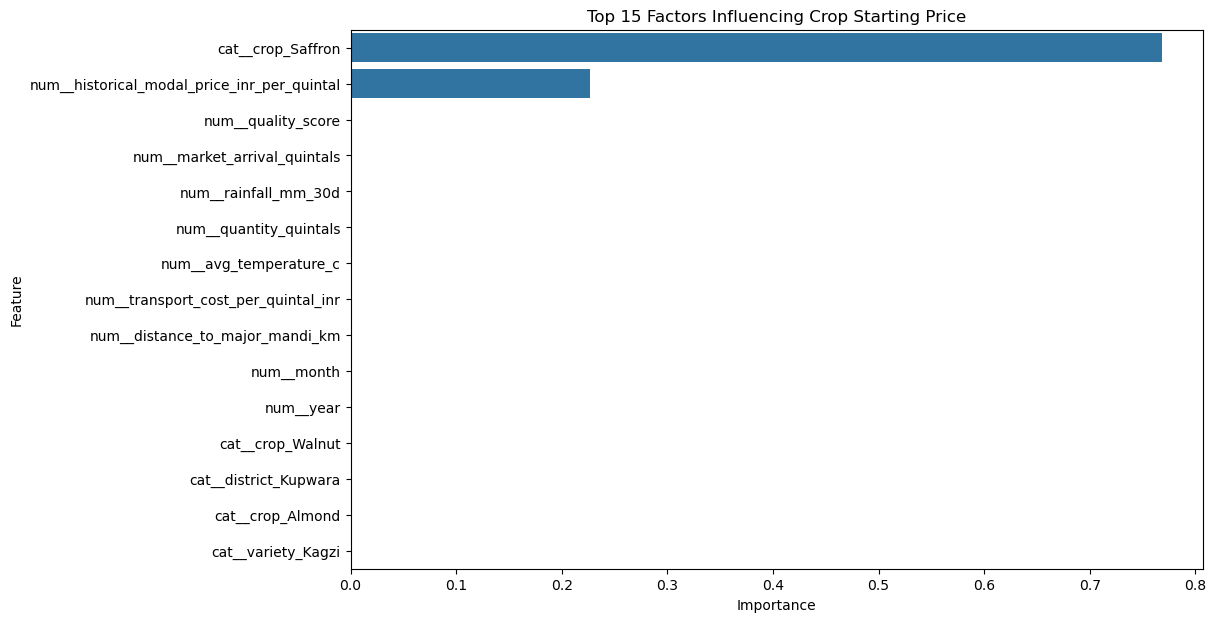

In [64]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Factors Influencing Crop Starting Price")

plt.show()

In [65]:
import os

os.makedirs("models", exist_ok=True)

print("Models folder created!")

Models folder created!


In [66]:
import joblib

best_model = models["Random Forest"]

joblib.dump(
    best_model,
    "models/kisanbid_model.pkl"
)

print("KisanBid model exported successfully!")

KisanBid model exported successfully!


In [67]:
import os

print(os.listdir("models"))

['kisanbid_model.pkl']


## Conclusion

In this notebook, we developed a Machine Learning workflow for AgriSense.

We started with an agricultural bidding dataset and prepared it for model training.

We then:

1. Cleaned categorical and invalid values.
2. Extracted useful information from listing dates.
3. Selected input features and the target variable.
4. Divided the dataset into training and testing sets.
5. Built preprocessing pipelines.
6. Trained four regression algorithms.
7. Evaluated and compared their performance.
8. Selected a model based on its MAE.
9. Saved the trained model using Joblib.
10. Tested the model using a new crop listing.
11. Examined feature importance.

The trained model can serve as the prediction component of the AgriSense platform.

### What comes next?

The next stage is to connect this saved model to a user interface where farmers can enter crop details and receive an estimated starting bid price.

This turns our Machine Learning experiment into a practical demonstration of an AI-assisted agricultural bidding platform.

### Project Limitation

The dataset used in this project should be treated according to its actual source and representativeness. If it is synthetic, the model's results demonstrate learning from generated data and should not be presented as proof of real-world agricultural price accuracy.

Further development should involve verified historical market data, testing on genuinely unseen market periods, and feedback from farmers and buyers.